In [88]:
from os import listdir
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [89]:
data = pd.DataFrame()
root = "/Users/bjcliang/Desktop/GSS/code"
files = listdir(root)
for num in files:
    if num.isnumeric():
        data_dir = [i for i in listdir(root+'/'+num) if ('ptb.csv' in i)]
        if len(data_dir)==0: continue
        data_dir = root+'/'+num+'/'+data_dir[0]
        df = pd.read_csv(data_dir)
        df['paper'] = int(num)
        data = pd.concat([data, df])

In [90]:
summary = pd.read_excel('/Users/bjcliang/Desktop/GSS/summary_datacoverage.xlsx')
pairs = dict(zip(summary['Paper'], summary['Perturbation']))

In [91]:
data = data[['type', 'paper', 'r_sq_adj']].dropna()
papers, tps, reps, news = [], [], [], []
for num in set(data['paper']):
    if num == 3323: continue
    papers.append(num)
    tps.append(pairs[int(num)])
    reps.append(list(data[(data['paper']==num) & 
                          (data['type']=='Replication')]['r_sq_adj'])[0])
    news.append(list(data[(data['paper']==num) & 
                          (data['type']==pairs[int(num)])]['r_sq_adj'])[0])

In [92]:
result = pd.DataFrame({'paper':papers, 'type':tps,
                       'replication': reps, 'perturb':news})

In [93]:
result['replication'].mean(), result['perturb'].mean()

(0.19647778475576755, 0.19293237016678746)

In [94]:
result

,paper,type,replication,perturb
0,6536,attend->postlife,0.237396,0.207085
1,7433,educ->degree,0.289147,0.283140
2,4619,educ->degree,0.057536,0.057472
3,1813,prestige->rincome,0.274772,0.241618
4,1814,size->xnorcsiz,0.057415,0.057415
5,1686,region->reg16,0.119380,0.121181
6,1569,size->xnorcsiz,0.177837,0.181919
7,1314,vote72->vote68,0.170121,0.166120
8,1965,income->rincome,0.160718,0.149239
9,1202,xnorcsiz->srcbelt,0.200211,0.200792


In [103]:
sns.scatterplot(x='replication', y='perturb', data=result)
sns.regplot(x='replication', y='perturb', lowess=True, scatter=False, data=result)
np.corrcoef(result['replication'], result['perturb'])

ValueError: Could not interpret value `replication` for parameter `x`

In [96]:
result = pd.DataFrame()
for x in set(data['paper']):
    df = pd.read_csv(f'/Users/bjcliang/Desktop/GSS/code/{x}/replication_{x}_ptb.csv')
    try: 
        temp = df[['type', 'year', 'r_sq_adj']].copy()
    except KeyError: continue
    pro_sig = []
    for i, row in df.iterrows(): 
        helper = [row[i] for i in dict(row) if 'pvalue' in i]
        pvalues = []
        for i in helper:
            if i != i: pvalues.append(100)
            elif type(i) == float: pvalues.append(i)
            elif type(i) == int: pvalues.append(i)
            elif type(i) == str: 
                if '*' in i: pvalues.append(0)
                else: print(helper); pvalues.append(0)
        pvalues = np.array(pvalues)
        pro_sig.append((pvalues<0.05).mean())
        
        
    temp['pro_sig'] = pro_sig
    result = result.append(temp)
result = result.reset_index(drop=True).copy()

[0.0, '0', 0.0, 0.0, '0', 0.0015, 0.0099]
[0.0, '0', 0.0, 0.0, '0', 0.0015, 0.0099]
[0.0, '0', 0.0, 0.0, '0', 0.0004, 0.1159]
[0.0, '0', 0.0, 0.0, '0', 0.0004, 0.1159]
[0.0, '0', 0.0, 0.0058, '0', 0.0504, 0.0078]
[0.0, '0', 0.0, 0.0058, '0', 0.0504, 0.0078]


In [97]:
result['is_replication'] = result['type'].apply(lambda x: 'replication' 
                                                if 'repli' in x.lower() else 'perturbation'
                                               )

<AxesSubplot:xlabel='is_replication', ylabel='pro_sig'>

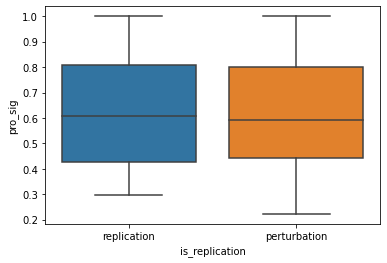

In [98]:
sns.boxplot(x='is_replication', y='pro_sig', data = result)

In [99]:
result.groupby('is_replication').mean()

,year,r_sq_adj,pro_sig
is_replication,,,
perturbation,1982.097561,0.194813,0.626014
replication,1981.850000,0.196478,0.632944


In [100]:
result.groupby('is_replication').median()

,year,r_sq_adj,pro_sig
is_replication,,,
perturbation,1980.0,0.198024,0.590909
replication,1980.0,0.188312,0.606618


In [85]:
def perc_sig_beta(row, org_pvalues):
    
    betas, pvalues = [], []

    for i in dict(row):
        if 'beta' in i: betas.append(row[i])
        if 'pvalue' in i: pvalues.append(row[i])
   
    #if x == 4619: print(org_pvalues, pvalues)
    
    betas = np.array([float(i) for i in betas])
    pvalues = np.array([float(i) for i in pvalues])
    org_pvalues = np.array([float(i) for i in org_pvalues]) 
    
    if len(betas)==0: 
        return (pvalues<=0.05).mean(), np.nan, np.nan
    
    if (org_pvalues<=0.05).sum()==0: print(x, org_pvalues)   
    perc_sig = (pvalues<=0.05).mean()
    mean_abs = abs(betas).mean()
    mean_abs_sig = abs(betas[org_pvalues<=0.05]).mean()
    return perc_sig, mean_abs, mean_abs_sig

In [87]:
perc_sig_beta(df.iloc[1], org_pvalues)

(1.0, 0.13719686428571426, 0.13719686428571426)

In [82]:
result = pd.DataFrame()
for x in set(data['paper']):
    if x == 196: continue
    if 
    df = pd.read_csv(f'/Users/bjcliang/Desktop/GSS/code/{x}/replication_{x}_ptb.csv')
    temp = df.copy()
    
    res = []; switch = False; org_pvalues = []
    for i, row in temp.iterrows(): 
        if row['type'].lower()=='original': continue
        if row['type'] == 'Replication': 
            org_pvalues = [row[i] for i in dict(row) if 'pvalue' in i]
        res.append(perc_sig_beta(row, org_pvalues))
    temp = temp[['type', 'year']]
    temp['paper'] = x
    
    temp['perc_sig'] = [i[0] for i in res]
    temp['mean_abs'] = [i[1] for i in res]
    temp['mean_abs_sig'] = [i[2] for i in res]
    
    result = result.append(temp)

result = result.reset_index(drop=True).copy()

6536
7433
4619
1813
1814
1686
1569
1314
1965
1202
2243
6340
5839
3164


ValueError: Length of values (3) does not match length of index (4)

significant in the published paper;
pick variables for 

betas for time forward
1. alternative variable
2. for index: alternative measurement
3. 